# Oscillatory flow in a compliant channel: streaming

This notebook computes the steady streaming (cycle-averaged) pressure generated by an oscillatory, pressure-driven flow in a weakly deformable two-dimensional channel, a phenomenon known as _elastoinertial rectification_ [RPC26]. It does so in two ways:

1. from the reduced, nonlinear PDE for the pressure of [PWC23], both by a perturbation expansion in the compliance number $\beta\ll1$ and by solving the PDE numerically;
2. from the effective-slip theory of [RPC26], the two-dimensional channel counterpart of the tube theory of [ZR24], with and without the contribution of advective inertia.

Throughout, the deformable wall is modeled as a Winkler foundation, $U_Y = P$. [RPC26] also consider the combined foundation model of [CV20] for a confined elastic layer, and [HPFC25] treat the analogous three-dimensional channel with a plate-like top wall.

## Credit

Initial version written by [Ivan C. Christov](http://christov.tmnt-lab.org), Purdue University.

## Notation

Each part of the notebook follows the paper it is based on, as far as practical. The correspondence is:

| This notebook | [PWC23] | [RPC26] | Meaning |
| --- | --- | --- | --- |
| $\mathrm{Wo}$ | $\alpha$ | $\mathrm{Wo}$ | Womersley number |
| $\beta$ | $\beta$ | $\beta$ | compliance (FSI) number |
| $\hat{\mathrm{St}} \equiv \gamma$ | $2\pi\beta St_f$ | $\gamma$ | ratio of flow to oscillation time scales |
| $T$, period $2\pi$ | $T/(2\pi)$, period $1$ | $T$ | time |
| $P_0$, $P_1$ | $P_0$, $P_1$ | $P_0$, $P_1$ | $\mathrm{O}(1)$ and $\mathrm{O}(\beta)$ pressure |
| $\mathfrak{f}_0$, $\mathfrak{f}_1$ | $\mathfrak{f}_0$, $\mathfrak{f}_1$ | $\mathfrak{f}_0$, &ndash; | flow-rate coefficients |
| $\mathfrak{f}_\mathrm{w}$ | &ndash; | $\mathfrak{f}_1$ | wall-shear coefficient |

Note that $\mathfrak{f}_1$ of [PWC23] and $\mathfrak{f}_1$ of [RPC26] are different quantities; we write the latter as $\mathfrak{f}_\mathrm{w}$.

The cycle average is $\langle\,\cdot\,\rangle := \frac{1}{2\pi}\int_0^{2\pi} (\,\cdot\,) \, dT$. As in [PWC23] and [RPC26], complex amplitudes are used with the real part understood, and $\mathrm{Re}[\cdot]$ is written out only inside nonlinear terms. For complex amplitudes $A$ and $B$, $\langle \mathrm{Re}[A e^{iT}]\,\mathrm{Re}[B e^{iT}] \rangle = \tfrac{1}{2}\mathrm{Re}[A^* B]$, where $^*$ denotes the complex conjugate.

# Preliminaries

In [1]:
# sympy setup
import sympy as sp
sp.init_printing()

# plotting customizations
from matplotlib import pyplot as plt
size=16
params = {'legend.fontsize': 'large',
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.875,
          'ytick.labelsize': size*0.875,
          'axes.titlepad': 25,
          'font.family': 'serif',
          'mathtext.fontset': 'cm'}
plt.rcParams.update(params)
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

%matplotlib inline
from matplotlib import colormaps

# numerics
import numpy as np
from scipy.integrate import solve_ivp, solve_bvp
from scipy.integrate import trapezoid, cumulative_trapezoid
from scipy.special import jv, iv

Unless stated otherwise, the plots use the reference parameters below, within the range considered by [RPC26] ($\mathrm{Wo} = 1$ to $3$, $\gamma = 0.5$ to $1.5$). $\beta$ is used only by the numerical solution of the PDE.

In [2]:
Wo_ref = 2.0
St_ref = 0.75
beta_ref = 0.1

# Method of Pande _et al._ (2023)

SymPy symbols.

In [3]:
beta, Wo, St = sp.symbols('beta, Wo, St', real=True, positive=True)
P, Z, T = sp.symbols('P, Z, T', real=True)

The governing PDE for the pressure $P(Z,T)$ is [PWC23]
$$
   \frac{\partial }{\partial Z} \left\{ \mathfrak{F}(\beta\,\mathrm{Re}[P];\mathrm{Wo}) \frac{\partial P}{\partial Z} \right\}  = \hat{\mathrm{St}} \frac{\partial P}{\partial T},
$$
where
$$
  \mathfrak{F}(\beta\,\mathrm{Re}[P]; \mathrm{Wo}) =
  \left(1 + \beta\,\mathrm{Re}[P]\right)
  \frac{1}{i {\mathrm{Wo}}^2}
  \left[1 - \frac{\tan\left(i^{3/2}{\mathrm{Wo}}\left(1 + \beta\,\mathrm{Re}[P]\right)/2\right)}{i^{3/2}{\mathrm{Wo}}\left(1 + \beta\,\mathrm{Re}[P]\right)/2}\right],
$$
subject to $P(0,T) = e^{iT}$ and $P(1,T) = 0$. Here, time is scaled so that the period is $2\pi$, whence $\hat{\mathrm{St}} := 2\pi\beta St_f$ in terms of the Strouhal number $St_f$ of [PWC23]. Only the real part of $P$ enters the deformed height, $1+\beta\,\mathrm{Re}[P]$; the physical pressure is $\mathrm{Re}[P]$.

## Numerical solution of the PDE

We turn the PDE into a semi-discrete system of ODEs by the [method of lines](https://reference.wolfram.com/language/tutorial/NDSolveMethodOfLines.html), using flux-conservative central differencing with the nonlinear terms staggered (see [\[GC19\]](https://arxiv.org/abs/1903.07568)).

On the grid $Z_j = j\,\Delta Z$ ($j=0,\dots,N-1$), with spacing $\Delta Z = 1/(N-1)$, let $\mathcal{P}_j(T) \approx P(Z_j,T)$. For the interior nodes ($j=1,\dots,N-2$),
$$
   \frac{d\mathcal{P}_j}{dT} = \frac{1}{\hat{\mathrm{St}}} \frac{ S_{j+1/2}\, \mathfrak{F}(\beta\,\mathrm{Re}[\mathcal{P}_{j+1/2}];\mathrm{Wo}) - S_{j-1/2}\, \mathfrak{F}(\beta\,\mathrm{Re}[\mathcal{P}_{j-1/2}];\mathrm{Wo})}{\Delta Z},
$$
where
$$
\begin{aligned}
  S_{j+1/2} &:= \left.\frac{\partial P}{\partial Z}\right|_{Z_{j+1/2}} \approx \frac{\mathcal{P}_{j+1} - \mathcal{P}_{j}}{\Delta Z}, &\qquad \mathcal{P}_{j+1/2} &\approx \frac{\mathcal{P}_{j+1} + \mathcal{P}_{j}}{2},\\
  S_{j-1/2} &:= \left.\frac{\partial P}{\partial Z}\right|_{Z_{j-1/2}} \approx \frac{\mathcal{P}_j - \mathcal{P}_{j-1}}{\Delta Z}, &\qquad \mathcal{P}_{j-1/2} &\approx \frac{\mathcal{P}_j + \mathcal{P}_{j-1}}{2}.
\end{aligned}
$$
At $Z=0$ ($j=0$) and $Z=1$ ($j=N-1$), we impose the Dirichlet BCs
$$
  \mathcal{P}_0(T) = e^{iT}, \qquad \mathcal{P}_{N-1}(T) = 0.
$$
As in [PWC23], we start from $P(Z,0) = 0$ and integrate long enough for the initial transient to decay.

In [4]:
# number of grid points
N = 500
# the grid and its spacing
Zj = np.linspace(0,1,num=N,endpoint=True)
dZ = Zj[1] - Zj[0]
# time span of numerical integration: 8 periods
Tmax = 8*(2*np.pi)

In [5]:
# only the real part of beta*P enters the deformed height, 1 + beta*Re[P]
def mathfrak_F(betaP,Wo):
  a = 1 + np.real(betaP)
  return a/(1j*Wo**2) \
           * (1 - np.tan(1j**(3/2)*Wo*a/2)/(1j**(3/2)*Wo*a/2))

In [6]:
def P_left_BC(T):
  return np.exp(1j*T)

def P_right_BC(T):
  return 0.

In [7]:
# semi-discrete ODE system's right-hand side, for the interior nodes j = 1, ..., N-2
def PWC23_PDE_RHS(T,P,beta,St,Wo):
  # neighbors of each interior node, using the Dirichlet BCs at the ends
  Pm1 = np.concatenate(([P_left_BC(T)], P[0:N-3]))
  Pp1 = np.concatenate((P[1:N-2], [P_right_BC(T)]))

  # values and slopes at j -/+ 1/2
  Pm12 = (P + Pm1)/2
  Pp12 = (Pp1 + P)/2
  Sm12 = (P - Pm1)/dZ
  Sp12 = (Pp1 - P)/dZ

  return (mathfrak_F(beta*Pp12,Wo)*Sp12 - mathfrak_F(beta*Pm12,Wo)*Sm12)/dZ/St

The `Radau` and `LSODA` methods of `solve_ivp` do not support complex-valued solutions.

The problem is stiff, so the explicit Runge&ndash;Kutta methods are slow. `BDF` works well.

In [8]:
my_beta = beta_ref
my_St = St_ref
my_Wo = Wo_ref

# integration method and solver tolerance(s)
intmeth = 'BDF'
tol = 1e-8

# zero initial condition, as in [PWC23]
Pic = np.zeros(N-2, dtype=complex)

# simulate the PDE
sol = solve_ivp(fun=lambda T, P: PWC23_PDE_RHS(T,P,my_beta,my_St,my_Wo),
                t_span=[0,Tmax], y0=Pic,
                method=intmeth, rtol=tol, atol=tol, dense_output=True)

## Perturbation expansion

For $\beta\ll1$, we expand $P = P_0 + \beta P_1 + \mathrm{O}(\beta^2)$ and $\mathfrak{F} = \mathfrak{f}_0(\mathrm{Wo}) + \beta\,\mathrm{Re}[P]\,\mathfrak{f}_1(\mathrm{Wo}) + \mathrm{O}(\beta^2)$ [PWC23], where
$$
\begin{aligned}
  \mathfrak{f}_0(\mathrm{Wo}) &= \frac{1}{i\mathrm{Wo}^2}\left[1-\frac{\tan\left(i^{3/2}\mathrm{Wo}/2\right)}{i^{3/2}\mathrm{Wo}/2}\right],\\
  \mathfrak{f}_1(\mathrm{Wo}) &= -\frac{1}{i\mathrm{Wo}^2}\tan^2\left(i^{3/2}\mathrm{Wo}/2\right).
\end{aligned}
$$
The cells below derive both coefficients from $\mathfrak{F}$ and check them against these formulas.

Unlike [PWC23], who take $\beta St_f = \mathrm{O}(\beta)$, so that the leading-order flow is quasi-steady, here we keep $\hat{\mathrm{St}} = \mathrm{O}(1)$. The $\mathrm{O}(1)$ problem is then an unsteady diffusion equation. The streaming pressure of [PWC23] is recovered as $\hat{\mathrm{St}}\to0$, which we check below.

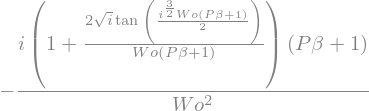

In [9]:
F = (1 + beta*P)*1/(sp.I*Wo**2) \
    * (1 - 1/(sp.I**sp.Rational(3,2)*Wo*(1+beta*P)/2)*sp.tan(sp.I**sp.Rational(3,2)*Wo*(1+beta*P)/2))
display(F)

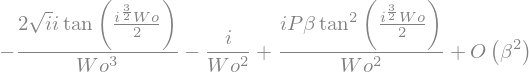

In [10]:
Fseries = sp.series(F,beta,0,2)
display(Fseries)

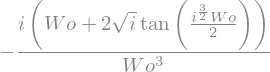

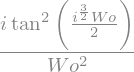

In [11]:
F0 = sp.limit(Fseries,beta,0).simplify()
display(F0)
F1 = sp.limit((Fseries-F0)/(beta*P),beta,0).simplify()
display(F1)

In [12]:
# check that F0 is the same as in Pande et al. (2023)
sp.Eq(F0,(1 - sp.tan(sp.I**sp.Rational(3,2)*Wo/2)/(sp.I**sp.Rational(3,2)*Wo/2))/(sp.I*Wo**2)).simplify()

In [13]:
# check that F1 is the same as in Pande et al. (2023)
sp.Eq(F1,-sp.tan(sp.I**sp.Rational(3,2)*Wo/2)**2/(sp.I*Wo**2)).simplify()

### At $\mathrm{O}(1)$

At $\mathrm{O}(1)$, we have
$$
\begin{aligned}
    \mathfrak{f}_0 \frac{\partial^2 P_0}{\partial Z^2} &= \hat{\mathrm{St}}\frac{\partial P_0}{\partial T},\\
    P_0(0,T) &= e^{i T},\\
    P_0(1,T) &= 0.
\end{aligned}
$$
The solution is of the form $P_0(Z,T) = P_{0,a}(Z) e^{i T}$, where 
$$
    \mathfrak{f}_0 P_{0,a}'' = i\hat{\mathrm{St}}P_{0,a},\quad P_{0,a}(0) = 1,\quad \text{and}\quad P_{0,a}(1) = 0.
$$

In [14]:
f0, f1 = sp.symbols('f0, f1')

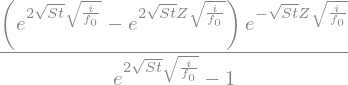

In [15]:
f = sp.Function('f')
P0asol = sp.dsolve(f0*f(Z).diff(Z,Z) - St*sp.I*f(Z),
                    f(Z), ics={f(0):1, f(1):0}).rhs.simplify()
display(P0asol)

In [16]:
lam_P0_PWC23 = sp.lambdify((Z,T,St,Wo), sp.re(P0asol.subs(f0,F0)*sp.exp(sp.I*T)))

### At $\mathrm{O}(\beta)$

At $\mathrm{O}(\beta)$, we have
$$
\begin{aligned}
    \mathfrak{f}_0 \frac{\partial^2 P_1}{\partial Z^2} +
    \mathfrak{f}_1 \frac{\partial}{\partial Z} \left(\mathrm{Re}[P_0]\frac{\partial P_0}{\partial Z}\right)
    &= \hat{\mathrm{St}} \frac{\partial P_1}{\partial T}, \\
    P_1(0,T) &= 0, \\
    P_1(1,T) &= 0.
\end{aligned}
$$
Since $\mathrm{Re}[P_0] = \tfrac{1}{2}\left(P_{0,a}e^{iT} + P_{0,a}^*e^{-iT}\right)$, the forcing has only a steady part and a second harmonic, so
$$
    P_1(Z,T) = P_{1,0,a}(Z) + P_{1,2,a}(Z) e^{2i T}.
$$
The steady term satisfies
$$
    \mathfrak{f}_0 \frac{d^2 P_{1,0,a}}{d Z^2} + \frac{1}{2} \mathfrak{f}_1 \frac{d}{d Z} \left(P_{0,a}^* \frac{d P_{0,a}}{d Z}\right) = 0, \qquad P_{1,0,a}(0) = P_{1,0,a}(1) = 0,
$$
and the streaming pressure is $\langle P_1 \rangle = \mathrm{Re}[P_{1,0,a}]$. Unlike in a tube, there is no storage term, because the cross-sectional area of the channel depends linearly on the pressure.

This ODE is elementary once its forcing term is written in real form. With $\zeta := 1-Z$ and $\kappa = \kappa_r + i\kappa_i$,
$$
  P_{0,a}^*\frac{dP_{0,a}}{dZ} = -\kappa\,\frac{\sinh(2\kappa_r \zeta)-i\sin(2\kappa_i \zeta)}{2|\sinh\kappa|^2},
$$
where $|\sinh\kappa|^2 = \tfrac{1}{2}\left[\cosh(2\kappa_r) - \cos(2\kappa_i)\right]$. Integrating twice and imposing $P_{1,0,a}(0) = P_{1,0,a}(1) = 0$ gives
\begin{align*}
  P_{1,0,a}(Z) &= -\frac{\mathfrak{f}_1}{2\mathfrak{f}_0}\left[W(Z) - (1-Z)W(0) - Z W(1)\right],\\
  W(Z) &= \frac{\kappa}{2|\sinh\kappa|^2}\left[\frac{\cosh(2\kappa_r \zeta)}{2\kappa_r} + i\,\frac{\cos(2\kappa_i \zeta)}{2\kappa_i}\right].
\end{align*}
Below, SymPy checks the identity and carries out the integration.

In [17]:
# kappa = kappa_r + i kappa_i, and zeta = 1 - Z
kr, ki = sp.symbols('kappa_r, kappa_i', real=True, nonzero=True)
kappa_c = kr + sp.I*ki
zeta = 1 - Z
P0a_c = sp.sinh(kappa_c*zeta)/sp.sinh(kappa_c)
abs_sinh2 = (sp.cosh(2*kr) - sp.cos(2*ki))/2
P0astar_dP0a = -kappa_c*(sp.sinh(2*kr*zeta) - sp.I*sp.sin(2*ki*zeta))/(2*abs_sinh2)

# check the identity at sample values of kappa
residual = sp.lambdify((Z, kr, ki), sp.conjugate(P0a_c)*P0a_c.diff(Z) - P0astar_dP0a)
my_res = max(abs(residual(my_Zval, 0.7, -1.3)) for my_Zval in np.linspace(0,1,11))
print(f'identity residual: {my_res:.1e}')

identity residual: 6.0e-16


In [18]:
# integrate f0 P'' = -(1/2) f1 (P0a* P0a')' twice, then impose P(0) = P(1) = 0
c0, c1 = sp.symbols('c0, c1')
dP10a = -sp.Rational(1,2)*f1*P0astar_dP0a/f0 + c1
P10asol = sp.integrate(dP10a, (Z, 0, Z)) + c0
P10asol = P10asol.subs(sp.solve([P10asol.subs(Z, 0), P10asol.subs(Z, 1)], [c0, c1]))

lam_P10a = sp.lambdify((Z, kr, ki, f0, f1), P10asol)

In [19]:
def f0_num(Wo):
  a = 1j**(3/2)*Wo/2
  return (1 - np.tan(a)/a)/(1j*Wo**2)

def f1_num(Wo):
  return -np.tan(1j**(3/2)*Wo/2)**2/(1j*Wo**2)

# P_{1,0,a}(Z) and the streaming pressure <P_1> = Re[P_{1,0,a}]
def lam_streamP_PWC23_complex(Z,St,Wo):
  f0 = f0_num(Wo)
  f1 = f1_num(Wo)
  kappa = np.sqrt(1j*St/f0)
  return lam_P10a(Z, kappa.real, kappa.imag, f0, f1)

def lam_streamP_PWC23(Z,St,Wo):
  return np.real(lam_streamP_PWC23_complex(Z,St,Wo))

As $\hat{\mathrm{St}}\to0$, $\langle P_1 \rangle$ tends to the result of [PWC23], $\tfrac{1}{4}Z(1-Z)\,\mathrm{Re}[\mathfrak{f}_1/\mathfrak{f}_0]$:

In [20]:
my_Wo = Wo_ref
my_Z = np.linspace(0,1,100,endpoint=True)
my_streamP_qs = 0.25*my_Z*(1-my_Z)*np.real(f1_num(my_Wo)/f0_num(my_Wo))

for my_St_small in [1e-1, 1e-2, 1e-3]:
  my_err = np.max(np.abs(lam_streamP_PWC23(my_Z,my_St_small,my_Wo) - my_streamP_qs))
  print(f'Wo = {my_Wo}, St = {my_St_small:g}: max difference = {my_err:.2e}')

Wo = 2.0, St = 0.1: max difference = 7.59e-03
Wo = 2.0, St = 0.01: max difference = 1.15e-03
Wo = 2.0, St = 0.001: max difference = 1.18e-04


The second-harmonic term satisfies
$$
    \mathfrak{f}_0 \frac{d^2 P_{1,2,a}}{d Z^2}
    + \frac{1}{2} \mathfrak{f}_1 \frac{d}{d Z} \left( P_{0,a} \frac{d P_{0,a}}{d Z} \right) - 2i \hat{\mathrm{St}} P_{1,2,a} = 0, \qquad P_{1,2,a}(0) = P_{1,2,a}(1) = 0.
$$
It does not contribute to the cycle average, so we do not solve it here.

## Numerical solution vs perturbation

We compare the pressure from the PDE (solid) with the leading-order perturbation solution, $\mathrm{Re}[P_0]$ (dashed), over the last computed period.

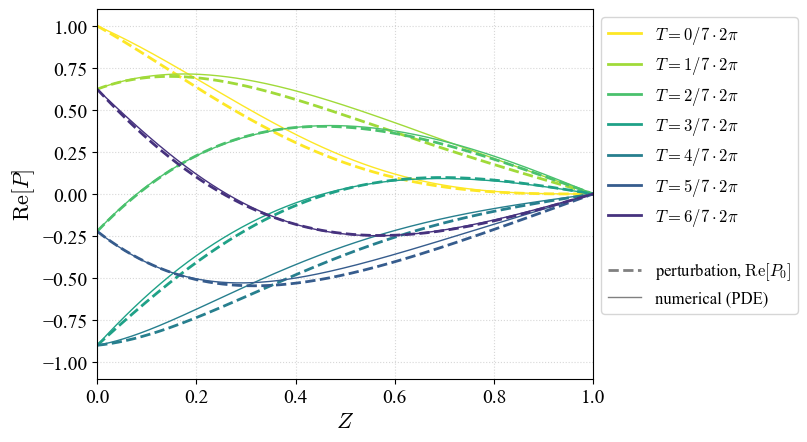

beta = 0.1, Wo = 2.0, St = 0.75


In [21]:
my_beta = beta_ref
my_St = St_ref
my_Wo = Wo_ref

ax = plt.gca()
ax.set_xlabel('$Z$')
ax.set_ylabel(r'$\mathrm{Re}[P]$')
ax.set_xlim(0, 1)
ax.set_ylim(-1.1, 1.1)

# https://matplotlib.org/stable/users/explain/colors/colormaps.html#sequential
cmap = colormaps['viridis_r']

T0 = Tmax-2*np.pi
jmax = 7
for j in range(0,jmax):
  Tj = T0+j/jmax*2*np.pi
  my_P0 = lam_P0_PWC23(Zj,Tj,my_St,my_Wo)
  ax.plot(Zj, my_P0, 
          lw=2, ls='dashed', color=cmap(j/jmax))
  Pj = np.concatenate(([P_left_BC(Tj)], sol.sol(Tj), [P_right_BC(Tj)]))
  ax.plot(Zj, np.real(Pj), lw=1, color=cmap(j/jmax))

ax.grid(alpha=0.5, linestyle='dotted')

# legend: one color per time, then the two line styles
from matplotlib.lines import Line2D
handles = [Line2D([], [], lw=2, color=cmap(j/jmax)) for j in range(jmax)]
labels = [rf'$T = {j}/{jmax} \cdot 2\pi$' for j in range(jmax)]
handles += [Line2D([], [], ls='', marker=''),
            Line2D([], [], lw=2, ls='dashed', color='gray'),
            Line2D([], [], lw=1, color='gray')]
labels += ['', r'perturbation, $\mathrm{Re}[P_0]$', 'numerical (PDE)']
ax.legend(handles, labels, bbox_to_anchor=(1, 1))

plt.show()

print(f'beta = {my_beta}, Wo = {my_Wo}, St = {my_St}')

### Streaming: PDE vs perturbation

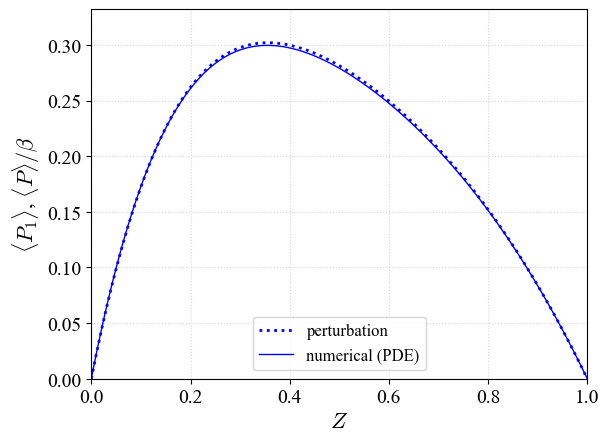

beta = 0.1, Wo = 2.0, St = 0.75


In [22]:
my_streamP = lam_streamP_PWC23(Zj,my_St,my_Wo)
# cycle average over the last computed period
my_Ts = np.linspace(T0,T0+2*np.pi,50,endpoint=True)

sol_space_time = np.concatenate(([P_left_BC(my_Ts)], sol.sol(my_Ts), [np.zeros_like(my_Ts)]))
my_numerical_streamP = np.real(trapezoid(sol_space_time,my_Ts,axis=1)/(2*np.pi))/my_beta

ax = plt.gca()
ax.set_xlabel('$Z$')
ax.set_ylabel(r'$\langle P_1 \rangle$, $\langle P \rangle/\beta$')
ax.set_xlim(0, 1)
ylim_max = float(1.1*max(np.max(my_streamP),
                         np.max(my_numerical_streamP)))
ax.set_ylim(0, ylim_max)

ax.plot(Zj, my_streamP, lw=2, ls='dotted', color='blue', label='perturbation')
ax.plot(Zj, my_numerical_streamP, lw=1, color='blue', label='numerical (PDE)')

ax.grid(alpha=0.5, linestyle='dotted')

ax.legend(loc='lower center')

plt.show()

print(f'beta = {my_beta}, Wo = {my_Wo}, St = {my_St}')

At $\beta = 0.1$, the streaming pressure from the PDE agrees with the $\mathrm{O}(\beta)$ perturbation result to within about 1%. The difference decreases as $\beta^2$, because the $\mathrm{O}(\beta^2)$ correction to the mean pressure vanishes: its forcing contains only odd harmonics.

# Method of Rade, Pande &amp; Christov (2026)

In [23]:
# fresh symbols for this section; this Wo (real) is a different SymPy symbol from the
# one above (real, positive), but lambdify treats both as 'Wo'
kappa = sp.symbols('kappa')
Wo, Y, Z, T = sp.symbols('Wo, Y, Z, T', real=True)

As in [PWC23], $P_0(Z,T) = P_{0,a}(Z) e^{iT}$, where
$$
  P_{0,a}(Z) = \frac{\sinh\big(\kappa(1-Z)\big)}{\sinh \kappa},\qquad \kappa(\mathrm{Wo}) := \sqrt{\frac{i\gamma}{\mathfrak{f}_0(\mathrm{Wo})}},\quad \gamma \equiv \hat{\mathrm{St}}.
$$
This is also the leading-order pressure of [RPC26] for a Winkler foundation.

In [24]:
P0a = sp.sinh(kappa*(1-Z))/sp.sinh(kappa)
P0 = P0a*sp.exp(sp.I*T)

The leading-order axial velocity is the Womersley profile [RPC26], $V_{Z,0}(Y,Z,T) = V_{Z,0,a}(Y,Z) e^{iT}$, where
$$
    V_{Z,0,a}(Y,Z) =
    \frac{1}{i\mathrm{Wo}^2}\left[1-\frac{\cos\left(i^{3/2} (1-2Y){\mathrm{Wo}}/2\right)}{\cos\left(i^{3/2} {\mathrm{Wo}}/2 \right)}\right] \left( -\frac{d P_{0,a}}{d Z} \right).
$$

In [25]:
Vz0a = 1/(sp.I*Wo**2)*(1 - sp.cos(sp.I**sp.Rational(3,2)*(1-2*Y)*Wo/2) \
                           /sp.cos(sp.I**sp.Rational(3,2)*Wo/2))*(-P0a.diff(Z))
Vz0 = Vz0a*sp.exp(sp.I*T)

From the continuity equation,
$$
  \frac{\partial V_{Y,0,a}}{\partial Y} + \frac{\partial V_{Z,0,a}}{\partial Z} = 0,
$$
the vertical velocity $V_{Y,0,a}$ is found by integrating in $Y$, with $V_{Y,0,a} = 0$ at $Y=0$.

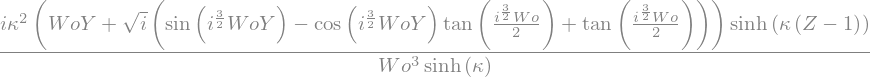

In [26]:
f = sp.Function('f')
Vy0a = sp.dsolve(f(Y).diff(Y) + Vz0a.diff(Z), f(Y), ics={f(0):0}).rhs.simplify()
display(Vy0a)
Vy0 = Vy0a*sp.exp(sp.I*T)

Following [RPC26], the $\mathrm{O}(\beta)$ mean flow is driven by an effective slip velocity at the undeformed wall (from Taylor-expanding the no-slip condition about $Y=1$), with wall displacement $U_{Y,0} = P_0$,
$$
  V_\mathrm{slip}(Z) := -\left.\left\langle P_0 \frac{\partial V_{Z,0}}{\partial Y} \right\rangle\right|_{Y=1},
$$
and by advective inertia, through $\widetilde{\langle V_{Z,1}\rangle}$ (evaluated in the next section). From $V_{Z,0,a}$ above,
$$
  V_\mathrm{slip}(Z) = \tfrac{1}{2}\mathrm{Re}\left[ \mathfrak{f}_\mathrm{w}(\mathrm{Wo})\, P_{0,a}^* \frac{dP_{0,a}}{dZ} \right], \qquad
  \mathfrak{f}_\mathrm{w}(\mathrm{Wo}) := \frac{i^{1/2}}{\mathrm{Wo}} \tan\left(i^{3/2}\mathrm{Wo}/2\right).
$$
Neglecting advective inertia for now, [RPC26]
$$
    \langle Q_1 \rangle = \int_0^1 \tfrac{1}{2} V_\mathrm{slip}(Z) \, dZ
    \qquad\text{and}\qquad
    \langle P_1 \rangle(Z) = 12 \int_0^Z \tfrac{1}{2} V_\mathrm{slip}(Z') \, dZ' - 12 Z \langle Q_1 \rangle,
$$
so that $\langle P_1 \rangle(0) = \langle P_1 \rangle(1) = 0$. With $W(Z)$, the antiderivative of $P_{0,a}^*\,dP_{0,a}/dZ$ from the [PWC23] part, both integrals are in closed form, 
$$
    \langle P_1 \rangle(Z) = 3\,\mathrm{Re}\big[\mathfrak{f}_\mathrm{w}\,\big(W(Z) - W(0) - Z\,[W(1) - W(0)]\big)\big].
$$
The cycle averages are evaluated as $\langle A B \rangle = \tfrac{1}{2}\mathrm{Re}[A^*B]$.

In [27]:
# antiderivative of P0a^* dP0a/dZ, from the identity in the [PWC23] part
def W_num(Z, kappa):
  kr, ki = kappa.real, kappa.imag
  abs_sinh2 = (np.cosh(2*kr) - np.cos(2*ki))/2
  zeta = 1 - Z
  return kappa/(2*abs_sinh2)*(np.cosh(2*kr*zeta)/(2*kr) + 1j*np.cos(2*ki*zeta)/(2*ki))

def fw_num(Wo):
  return np.sqrt(1j)/Wo*np.tan(1j**(3/2)*Wo/2)

# streaming pressure of [RPC26] without advective inertia, 
# <P1> = 12 int_0^Z V_slip/2 dZ' - 12 Z <Q1>, with V_slip = Re[fw P0a^* dP0a/dZ]/2
def lam_streamP_RPC26(Z, St, Wo):
  kappa = np.sqrt(1j*St/f0_num(Wo))
  W0, W1 = W_num(0, kappa), W_num(1, kappa)
  return 3*np.real(fw_num(Wo)*(W_num(Z, kappa) - W0 - Z*(W1 - W0)))

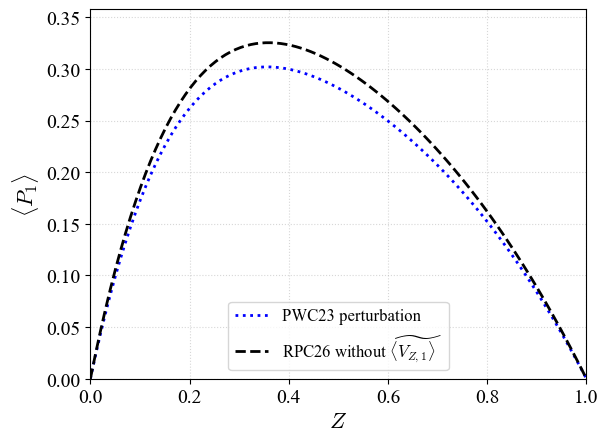

Wo = 2.0, St = 0.75


In [28]:
my_St = St_ref
my_Wo = Wo_ref

my_Z = np.linspace(0,1,100,endpoint=True)
my_streamP_RPC26 = lam_streamP_RPC26(my_Z,my_St,my_Wo)
my_streamP_PWC23 = lam_streamP_PWC23(my_Z,my_St,my_Wo)

ax = plt.gca()
ax.set_xlabel('$Z$')
ax.set_ylabel(r'$\langle P_1 \rangle$')
ax.set_xlim(0, 1)
ylim_max = float(1.1*max(np.max(my_streamP_RPC26),
                         np.max(my_streamP_PWC23)))
ax.set_ylim(0, ylim_max)

ax.plot(my_Z, my_streamP_PWC23, ls='dotted', color='blue', lw=2,
        label='PWC23 perturbation')
ax.plot(my_Z, my_streamP_RPC26, ls='dashed', color='black', lw=2,
        label=r'RPC26 without $\widetilde{\langle V_{Z,1}\rangle}$')

ax.grid(alpha=0.5, linestyle='dotted')

ax.legend(loc='lower center')

plt.show()

print(f'Wo = {my_Wo}, St = {my_St}')

## How the two formulations differ

Without advective inertia, both theories determine the streaming pressure from a mean-flux balance. In [PWC23], from the $\mathrm{O}(\beta)$ steady equation above,
$$
  \mathfrak{f}_0(\mathrm{Wo}) \frac{d^2 P_{1,0,a}}{dZ^2} = -\tfrac{1}{2}\mathfrak{f}_1(\mathrm{Wo}) \frac{d}{dZ}\left(P_{0,a}^*\frac{dP_{0,a}}{dZ}\right), \qquad \langle P_1\rangle = \mathrm{Re}[P_{1,0,a}],
$$
while in [RPC26], differentiating the formula for $\langle P_1 \rangle$ twice,
$$
  \frac{1}{12} \frac{d^2 \langle P_1\rangle}{dZ^2} = \mathrm{Re}\left[\tfrac{1}{4} \mathfrak{f}_\mathrm{w}(\mathrm{Wo}) \frac{d}{dZ}\left(P_{0,a}^*\frac{dP_{0,a}}{dZ}\right)\right].
$$
The two differ in two ways:

1. **Resistance to the mean flow.** [PWC23] use the oscillatory (Womersley) coefficient $\mathfrak{f}_0(\mathrm{Wo})$ for the mean flow too, whereas [RPC26] use the steady Poiseuille value $1/12$.
2. **Flux generated by the wall motion.** In [PWC23], it comes from the Womersley flux in the instantaneously deformed channel, with coefficient $-\tfrac{1}{2}\mathfrak{f}_1$. In [RPC26], it comes from the slip velocity at the undeformed wall, with coefficient $\tfrac{1}{4}\mathfrak{f}_\mathrm{w}$.

As $\mathrm{Wo}\to0$, $\mathfrak{f}_0 \to \tfrac{1}{12}$ and $-\tfrac{1}{2}\mathfrak{f}_1, \tfrac{1}{4}\mathfrak{f}_\mathrm{w} \to -\tfrac{1}{8}$, so the two theories agree. The coefficients separate as $\mathrm{Wo}$ grows:

In [29]:
print(f"{'Wo':>5} {'f0':>17} {'1/12':>6} {'-f1/2':>17} {'fw/4':>17}")
for my_Wo in [0.1, 1, 2, 3]:
  print(f'{my_Wo:5.1f} {f0_num(my_Wo):17.4f} {1/12:6.3f} {-f1_num(my_Wo)/2:17.4f} {fw_num(my_Wo)/4:17.4f}')

   Wo                f0   1/12             -f1/2              fw/4
  0.1    0.0833-0.0001j  0.083   -0.1250+0.0002j   -0.1250+0.0001j
  1.0    0.0825-0.0082j  0.083   -0.1221+0.0205j   -0.1240+0.0103j
  2.0    0.0717-0.0286j  0.083   -0.0877+0.0635j   -0.1107+0.0359j
  3.0    0.0460-0.0410j  0.083   -0.0283+0.0654j   -0.0789+0.0518j


At the reference parameters ($\mathrm{Wo}=2$), the coefficients already differ noticeably, and the peak streaming pressure of [PWC23] in the plot before this section is about 7% below that of [RPC26] without advective inertia. (In a tube, the [PWC23] streaming pressure is instead the larger of the two.) The comparison with simulations at the end shows the same trend.

## Evaluating the advective inertia's contribution

Next, we evaluate the cycle-averaged advective inertia,
$$
  \left\langle V_{Y,0} \frac{\partial V_{Z,0}}{\partial Y} + V_{Z,0} \frac{\partial V_{Z,0}}{\partial Z} \right\rangle = \left\langle V_{Y,0} \frac{\partial V_{Z,0}}{\partial Y} \right\rangle + \left\langle V_{Z,0} \frac{\partial V_{Z,0}}{\partial Z} \right\rangle.
$$

In [30]:
inertia_avg_term1 = sp.Rational(1,2)*sp.re(sp.conjugate(Vy0)*Vz0.diff(Y))
inertia_avg_term2 = sp.Rational(1,2)*sp.re(sp.conjugate(Vz0)*Vz0.diff(Z))

These expressions are lengthy, so we evaluate them numerically. Closed-form approximations for small $\mathrm{Wo}$ are given in [RPC26, Appendix A].

Following [RPC26], $\widetilde{\langle V_{Z,1}\rangle}$ satisfies the BVP
$$
  \frac{\mathrm{Wo}^2}{\gamma} \left\langle V_{Y,0} \frac{\partial V_{Z,0}}{\partial Y} + V_{Z,0} \frac{\partial V_{Z,0}}{\partial Z} \right\rangle =  \frac{\partial^2 \widetilde{\langle V_{Z,1}\rangle}}{\partial Y^2},
  \qquad
  \widetilde{\langle V_{Z,1}\rangle}|_{Y=0} = \widetilde{\langle V_{Z,1}\rangle}|_{Y=1} = 0.
$$
We solve it by integrating twice in $Y$, and check the result against `solve_bvp` at one value of $Z$.

In [31]:
avg_Vz1_adv_forcing = sp.lambdify((Y,Z,St,Wo), Wo**2/St*(inertia_avg_term1+inertia_avg_term2).subs(kappa,sp.sqrt(sp.I*St/F0)))

In [32]:
# the BVP is solved by integrating twice in Y, then subtracting the linear part so that V(1) = 0
my_Y = np.linspace(0, 1, 801)

# tilde<V_{Z,1}> on the grid my_Y, for an array of Z values, shape (Y, Z)
def Vz1_adv_field(Z, St, Wo):
  F = np.broadcast_to(avg_Vz1_adv_forcing(my_Y[:, None], np.atleast_1d(Z)[None, :], St, Wo), (my_Y.size, np.size(Z)))
  V = cumulative_trapezoid(cumulative_trapezoid(F, my_Y, axis=0, initial=0), my_Y, axis=0, initial=0)
  return V - my_Y[:, None]*V[-1]

def Vz1_adv(Z, St, Wo):
  return Vz1_adv_field(Z, St, Wo)[:, 0]

# int_0^1 tilde<V_{Z,1}> dY, for scalar or array Z
def yint_Vz1_adv(Z, St, Wo):
  out = trapezoid(Vz1_adv_field(Z, St, Wo), my_Y, axis=0)
  return out[0] if np.isscalar(Z) else out

In [33]:
# check against solve_bvp at one value of Z
def avg_Vz1_ode(Y, V, Z, St, Wo):
  return np.vstack((V[1], avg_Vz1_adv_forcing(Y, Z, St, Wo)))

my_Zval = 0.3
sol = solve_bvp(lambda Y, V: avg_Vz1_ode(Y, V, my_Zval, St_ref, Wo_ref), 
                lambda Va, Vb: np.array([Va[0], Vb[0]]),
                my_Y, np.zeros((2, my_Y.size)), tol=1e-9)
my_err = np.max(np.abs(Vz1_adv(my_Zval, St_ref, Wo_ref) - sol.sol(my_Y)[0]))
print(f'Z = {my_Zval}: max |direct - solve_bvp| = {my_err:.1e}',
      f'(max |V| = {np.max(np.abs(sol.sol(my_Y)[0])):.2e})')

Z = 0.3: max |direct - solve_bvp| = 3.5e-08 (max |V| = 3.18e-02)


Next, we plot (a) $\widetilde{\langle V_{Z,1}\rangle}$ against $Y$ at several $Z$ near the inlet, where it is largest; (b) $\widetilde{\langle V_{Z,1}\rangle}$ over the $(Z,Y)$ plane, with its zero contour; and (c) its cross-sectional integral, which enters $\langle P_1 \rangle$ below, with the profiles in (a), each normalized by its maximum, as an inset. These coincide to within 1%: the profile keeps nearly the same shape along the channel; only its amplitude varies, changing sign near $Z \approx 0.65$.

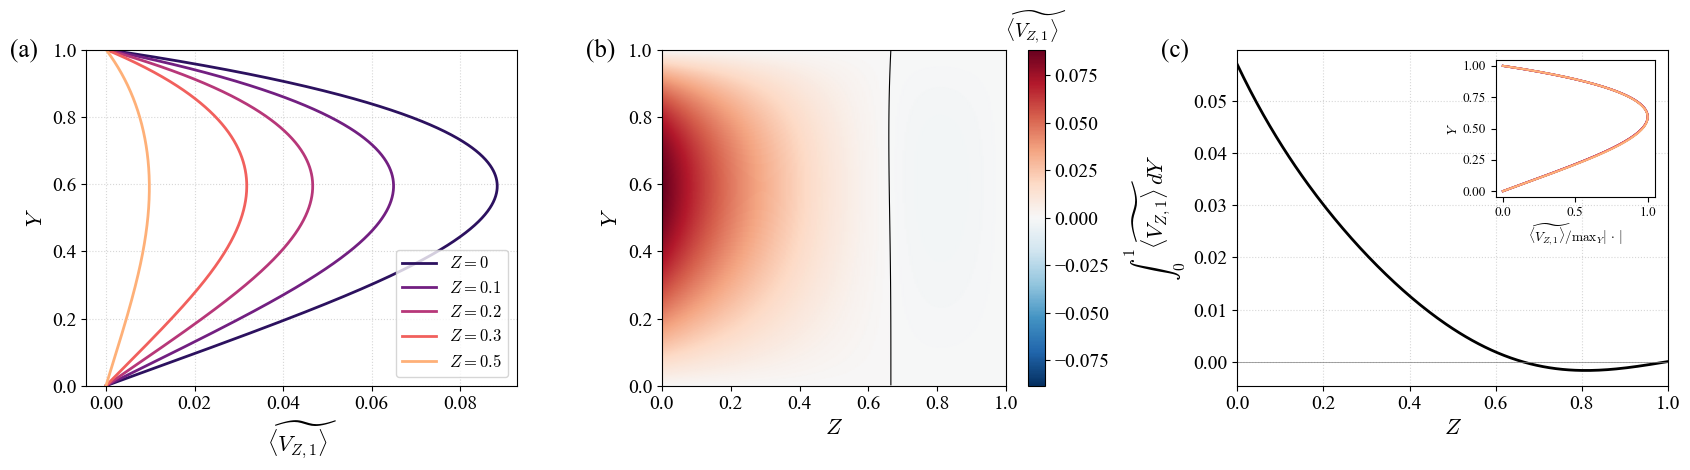

Wo = 2.0, St = 0.75


In [34]:
import matplotlib.transforms as mtransforms

my_St = St_ref
my_Wo = Wo_ref

# advective-inertia contribution on a grid of Z values, shape (Y, Z)
my_Zs = np.linspace(0, 1, 201)
my_V = Vz1_adv_field(my_Zs, my_St, my_Wo)
my_int = trapezoid(my_V, my_Y, axis=0)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) profiles at several Z near the inlet
cmap = colormaps['magma']
for j, my_Zval in enumerate([0, 0.1, 0.2, 0.3, 0.5]):
  i = np.argmin(np.abs(my_Zs - my_Zval))
  axs[0].plot(my_V[:, i], my_Y,
              lw=2, color=cmap((j+1)/6), label=f'$Z = {my_Zval}$')
axs[0].set_xlabel(r'$\widetilde{\langle V_{Z,1}\rangle}$')
axs[0].set_ylabel('$Y$')
axs[0].set_ylim(0, 1)
axs[0].grid(alpha=0.5, linestyle='dotted')
axs[0].legend()

# (b) over the (Z, Y) plane, with the zero contour
my_vmax = np.abs(my_V).max()
pc = axs[1].pcolormesh(my_Zs, my_Y, my_V, 
                       cmap='RdBu_r', vmin=-my_vmax, vmax=my_vmax, shading='gouraud')
# zero contour, away from the walls (where the velocity vanishes identically)
axs[1].contour(my_Zs, my_Y[1:-1], my_V[1:-1], 
               levels=[0], colors='black', linewidths=0.8)
cbar = fig.colorbar(pc, ax=axs[1])
cbar.ax.set_title(r'$\widetilde{\langle V_{Z,1}\rangle}$', fontsize=size*0.875, pad=8)
axs[1].set_xlabel('$Z$')
axs[1].set_ylim(0, 1)
axs[1].set_ylabel('$Y$')

# (c) cross-sectional integral along Z, with the profiles from (a), each normalized by its maximum, as an inset
axs[2].plot(my_Zs, my_int, lw=2, color='black')
axs[2].axhline(0, color='gray', lw=0.5)
axs[2].set_xlabel('$Z$')
axs[2].set_ylabel(r'$\int_0^1 \widetilde{\langle V_{Z,1}\rangle} \, dY$')
axs[2].set_xlim(0, 1)
axs[2].grid(alpha=0.5, linestyle='dotted')
inset = axs[2].inset_axes([0.6, 0.56, 0.37, 0.41])
for j, my_Zval in enumerate([0, 0.1, 0.2, 0.3, 0.5]):
  i = np.argmin(np.abs(my_Zs - my_Zval))
  inset.plot(my_V[:, i]/np.abs(my_V[:, i]).max(), my_Y, color=cmap((j+1)/6))
inset.set_xlabel(r'$\widetilde{\langle V_{Z,1}\rangle} / \mathrm{max}_Y |\,\cdot\,|$', fontsize=size*0.6, labelpad=2)
inset.set_ylabel('$Y$', fontsize=size*0.6, labelpad=2)
inset.tick_params(labelsize=size*0.6)

# panel labels, as in theory_steady/steady_FSI_shear_thinning.ipynb
trans = mtransforms.ScaledTranslation(-55/72, -5/72, fig.dpi_scale_trans)
for ax, my_label in zip(axs, ['(a)', '(b)', '(c)']):
  ax.text(0.0, 1.0, my_label, fontsize=size + 2, transform=ax.transAxes + trans)

fig.tight_layout()
plt.show()

print(f'Wo = {my_Wo}, St = {my_St}')

Now, we redo the $\langle P_1 \rangle$ plot including $\widetilde{\langle V_{Z,1}\rangle}$. From [RPC26],
$$
    \langle Q_1 \rangle = \int_0^1 \left[ \tfrac{1}{2} V_\mathrm{slip}(Z) + \int_0^1 \widetilde{\langle V_{Z,1} \rangle} \, dY \right] dZ
$$
and
$$
    \langle P_1 \rangle(Z) = 12 \int_0^Z \left[ \tfrac{1}{2} V_\mathrm{slip}(Z') + \int_0^1 \widetilde{\langle V_{Z,1} \rangle} \, dY \right] dZ' - 12 Z \langle Q_1 \rangle.
$$

In [35]:
my_St = St_ref
my_Wo = Wo_ref
my_Z = np.linspace(0,1,100,endpoint=True)

my_streamP_RPC26 = lam_streamP_RPC26(my_Z,my_St,my_Wo)

my_yint_Vz1_adv = yint_Vz1_adv(my_Z,my_St,my_Wo)

my_streamP_RPC26_w_Vz1_adv = my_streamP_RPC26 \
                             + 12*cumulative_trapezoid(my_yint_Vz1_adv,my_Z,initial=0) \
                             - 12*my_Z*trapezoid(my_yint_Vz1_adv,my_Z)

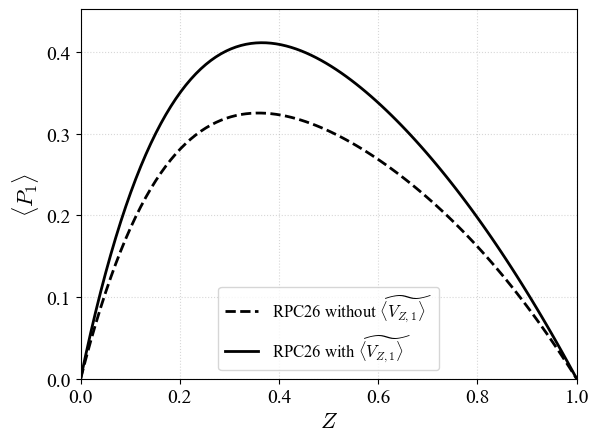

Wo = 2.0, St = 0.75


In [36]:
ax = plt.gca()
ax.set_xlabel('$Z$')
ax.set_ylabel(r'$\langle P_1 \rangle$')
ax.set_xlim(0, 1)
ylim_max = float(1.1*max(np.max(my_streamP_RPC26),
                         np.max(my_streamP_RPC26_w_Vz1_adv)))
ax.set_ylim(0, ylim_max)

ax.plot(my_Z, my_streamP_RPC26, lw=2, ls='dashed', color='black',
        label=r'RPC26 without $\widetilde{\langle V_{Z,1}\rangle}$')
ax.plot(my_Z, my_streamP_RPC26_w_Vz1_adv, lw=2, color='black',
        label=r'RPC26 with $\widetilde{\langle V_{Z,1}\rangle}$')

ax.grid(alpha=0.5, linestyle='dotted')

ax.legend()

plt.show()

print(f'Wo = {my_Wo}, St = {my_St}')

At the reference parameters, advective inertia raises the peak streaming pressure by about a quarter. As [RPC26] point out, neglecting it, as the reduced PDE of [PWC23] does, leads to $\mathrm{O}(1)$ errors in $\langle P_1 \rangle$.

# Comparison with ALE-FSI simulation data

The cycle-averaged pressures $\langle P \rangle/\beta$ below are from the 2D ALE-FSI simulations of [RPC26] at $\gamma = 1$ (their Fig. 11(b)), digitized from the vector graphics of that figure. The simulations resolve a confined elastic layer, which [RPC26] model with the combined foundation of [CV20]. At these parameters, its corrections to the Winkler foundation change the theoretical $\langle P_1 \rangle$ by only a few percent.

In [37]:
# cycle-averaged pressure <P>/beta from the ALE-FSI simulations of [RPC26] (their Fig. 11(b), gamma = 1)
sims = [
  dict(Wo=1, gamma=1.0, color='#440154',
       Z=np.array([0.0, 0.0301, 0.0601, 0.0902, 0.1202, 0.1503, 0.1804, 0.2104, 0.2405, 0.2705, 0.3006, 0.3307, 0.3607, 0.3908, 0.4208, 0.4509, 0.481, 0.511, 0.5411, 0.5711, 0.6012, 0.6313, 0.6613, 0.6914, 0.7214, 0.7515, 0.7816, 0.8116, 0.8417, 0.8717, 0.9018, 0.9319, 0.9619, 0.992]),
       P=np.array([-0.0003, 0.067, 0.1526, 0.2151, 0.2647, 0.304, 0.3346, 0.3576, 0.374, 0.3847, 0.3904, 0.392, 0.3899, 0.3848, 0.3771, 0.3671, 0.3552, 0.3416, 0.3266, 0.3103, 0.293, 0.2747, 0.2557, 0.2358, 0.2152, 0.194, 0.1723, 0.1499, 0.127, 0.1036, 0.0798, 0.0554, 0.0303, 0.0049])),
  dict(Wo=2, gamma=1.0, color='#21908C',
       Z=np.array([0.0, 0.0301, 0.0601, 0.0902, 0.1202, 0.1503, 0.1804, 0.2104, 0.2405, 0.2705, 0.3006, 0.3307, 0.3607, 0.3908, 0.4208, 0.4509, 0.481, 0.511, 0.5411, 0.5711, 0.6012, 0.6313, 0.6613, 0.6914, 0.7214, 0.7515, 0.7816, 0.8116, 0.8417, 0.8717, 0.9018, 0.9319, 0.9619, 0.992]),
       P=np.array([-0.0003, 0.0775, 0.1819, 0.2612, 0.3258, 0.3784, 0.4205, 0.453, 0.4771, 0.4939, 0.5041, 0.5088, 0.5085, 0.5039, 0.4956, 0.4841, 0.4698, 0.4531, 0.4342, 0.4134, 0.3911, 0.3672, 0.3421, 0.3157, 0.2883, 0.2599, 0.2306, 0.2004, 0.1693, 0.1373, 0.1047, 0.0712, 0.0367, 0.0014])),
  dict(Wo=3, gamma=1.0, color='#E3B505',
       Z=np.array([0.0, 0.0301, 0.0601, 0.0902, 0.1202, 0.1503, 0.1804, 0.2104, 0.2405, 0.2705, 0.3006, 0.3307, 0.3607, 0.3908, 0.4208, 0.4509, 0.481, 0.511, 0.5411, 0.5711, 0.6012, 0.6313, 0.6613, 0.6914, 0.7214, 0.7515, 0.7816, 0.8116, 0.8417, 0.8717, 0.9018, 0.9319, 0.9619, 0.992]),
       P=np.array([-0.0003, 0.0692, 0.1747, 0.2597, 0.3329, 0.3955, 0.4479, 0.4909, 0.5249, 0.551, 0.5697, 0.5818, 0.588, 0.5887, 0.5845, 0.5759, 0.5632, 0.5469, 0.5271, 0.5043, 0.4787, 0.4505, 0.4201, 0.3875, 0.3531, 0.317, 0.2794, 0.2405, 0.2003, 0.1592, 0.1173, 0.0747, 0.0314, -0.0126])),
]

In [38]:
# streaming pressure from each theory, at each simulation's parameters
my_Z = np.linspace(0,1,100,endpoint=True)

for sim in sims:
  my_St = sim['gamma']
  my_Wo = sim['Wo']
  sim['PWC23'] = lam_streamP_PWC23(my_Z,my_St,my_Wo)
  sim['RPC26'] = lam_streamP_RPC26(my_Z,my_St,my_Wo)
  my_yint_Vz1_adv = yint_Vz1_adv(my_Z,my_St,my_Wo)
  sim['RPC26_adv'] = sim['RPC26'] \
                     + 12*cumulative_trapezoid(my_yint_Vz1_adv,my_Z,initial=0) \
                     - 12*my_Z*trapezoid(my_yint_Vz1_adv,my_Z)

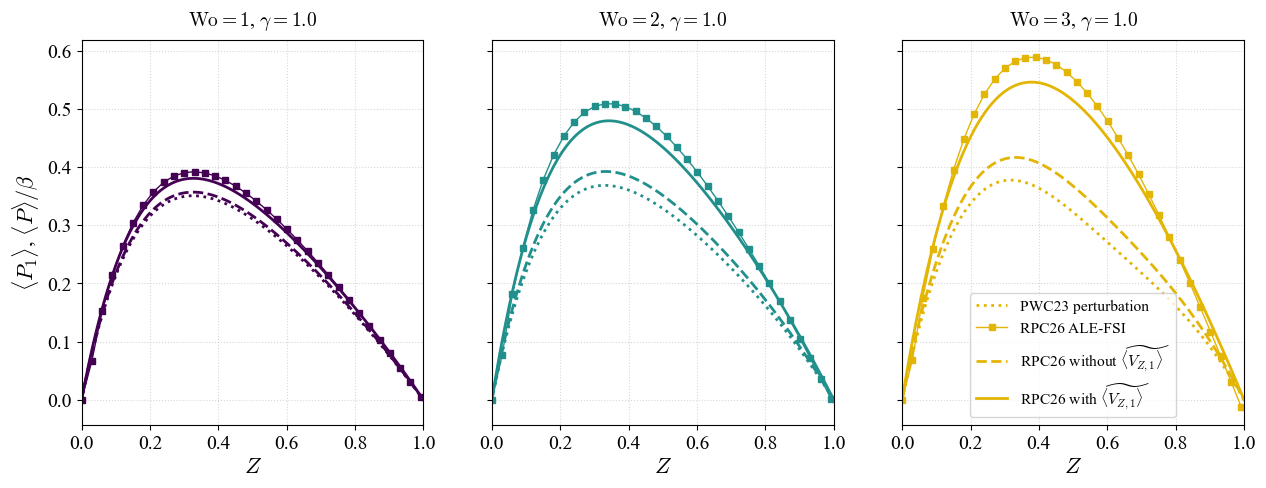

In [39]:
fig, axs = plt.subplots(1, len(sims), figsize=(15,5), sharey=True)

for ax, sim in zip(axs, sims):
  my_color = sim['color']
  ax.plot(my_Z, sim['PWC23'], lw=2, ls='dotted', color=my_color,
          label='PWC23 perturbation')
  ax.plot(sim['Z'], sim['P'], 's-', lw=1, ms=4, color=my_color,
          label='RPC26 ALE-FSI')
  ax.plot(my_Z, sim['RPC26'], lw=2, ls='dashed', color=my_color,
          label=r'RPC26 without $\widetilde{\langle V_{Z,1}\rangle}$')
  ax.plot(my_Z, sim['RPC26_adv'], lw=2, color=my_color,
          label=r'RPC26 with $\widetilde{\langle V_{Z,1}\rangle}$')
  ax.set_title(rf"$\mathrm{{Wo}} = {sim['Wo']}$, $\gamma = {sim['gamma']}$",
               fontsize=size*0.875, pad=10)
  ax.set_xlabel('$Z$')
  ax.set_xlim(0, 1)
  ax.grid(alpha=0.5, linestyle='dotted')

axs[0].set_ylabel(r'$\langle P_1 \rangle$, $\langle P \rangle/\beta$')
axs[-1].legend(loc='lower center', fontsize=size*0.7)

plt.show()

With advective inertia included, the theory of [RPC26] agrees closely with the ALE-FSI data for all three Womersley numbers, with a slight underprediction that grows with $\mathrm{Wo}$, as noted by [RPC26]. The perturbation solution of the reduced PDE of [PWC23], and the theory of [RPC26] without advective inertia, underpredict the streaming pressure, increasingly so as $\mathrm{Wo}$ grows.

# Summary

- The numerical solution of the reduced PDE of [PWC23] agrees with its $\mathrm{O}(\beta)$ perturbation solution, and the latter reduces to the closed-form result of [PWC23] as $\hat{\mathrm{St}}\to0$.
- Without advective inertia, the formulations of [PWC23] and [RPC26] differ in the resistance to the mean flow and in the flux generated by the wall motion. They agree as $\mathrm{Wo}\to0$ and separate as $\mathrm{Wo}$ grows.
- Advective inertia, which [RPC26] include but the reduced PDE of [PWC23] does not, is a large effect at the parameters of the ALE-FSI simulations. Including it brings the theory into close agreement with the simulations.

# References

[CV20] T. G. J. Chandler, D. Vella, Validity of Winkler's mattress model for thin elastomeric layers: beyond Poisson's ratio, _Proc. R. Soc. A_ **476** (2020) 20200551. [doi:10.1098/rspa.2020.0551](https://doi.org/10.1098/rspa.2020.0551); [arXiv:2010.11133](https://arxiv.org/abs/2010.11133)

[GC19] A. A. Ghodgaonkar, I. C. Christov, Solving nonlinear parabolic equations by a strongly implicit finite difference scheme: applications to the finite speed spreading of non-Newtonian viscous gravity currents, in: _Applied Wave Mathematics II_, Springer, 2019, pp. 305&ndash;342. [doi:10.1007/978-3-030-29951-4_14](https://doi.org/10.1007/978-3-030-29951-4_14); [arXiv:1903.07568](https://arxiv.org/abs/1903.07568)

[HPFC25] A. Huang, S. D. Pande, J. Feng, I. C. Christov, Oscillatory flows in three-dimensional deformable microchannels, _J. Fluid Mech._ **1022** (2025) A38. [doi:10.1017/jfm.2025.10771](https://doi.org/10.1017/jfm.2025.10771); [arXiv:2504.05132](https://arxiv.org/abs/2504.05132)

[PWC23] S. D. Pande, X. Wang, I. C. Christov, Oscillatory flows in compliant conduits at arbitrary Womersley number, _Phys. Rev. Fluids_ **8** (2023) 124102. [doi:10.1103/PhysRevFluids.8.124102](https://doi.org/10.1103/PhysRevFluids.8.124102); [arXiv:2304.00543](https://arxiv.org/abs/2304.00543)

[RPC26] U. M. Rade, S. D. Pande, I. C. Christov, Theory and simulation of elastoinertial rectification of oscillatory flows in two-dimensional deformable rectangular channels, _Phys. Rev. Fluids_ **11** (2026) 074102. [doi:10.1103/zk9v-13sn](https://doi.org/10.1103/zk9v-13sn); [arXiv:2505.22799](https://arxiv.org/abs/2505.22799)

[ZR24] X. Zhang, B. Rallabandi, Elasto-inertial rectification of oscillatory flow in an elastic tube, _J. Fluid Mech._ **996** (2024) A16. [doi:10.1017/jfm.2024.612](https://doi.org/10.1017/jfm.2024.612); [arXiv:2404.02292](https://arxiv.org/abs/2404.02292)